# PROYEK AKHIR SAINS DATA (IF2515403)
## BAB 3: DATA PREPARATION (PENYIAPAN DATA)
### Fokus Jobdesk: Missing Values, Handling Outliers, & Class Imbalance
**Topik**: Klasifikasi Tingkat Risiko Gangguan Tidur Berdasarkan Pola Hidup dan Biometrik  
**Dataset**: `dataset_GANGGUAN_TIDUR.csv` (100.000 baris × 32 kolom)

---

### Gambaran Umum & Batasan Pengerjaan Jobdesk
Notebook ini menyelesaikan tahapan penyiapan data sesuai dengan alur CRISP-DM dan pembagian *jobdesk* kelompok:
1. **Verifikasi Integritas & Retensi Objek Data**:
   - Seluruh 32 kolom awal (termasuk kolom identitas `person_id`) **dipertahankan utuh**. Eliminasi atau seleksi fitur tidak dilakukan di sini karena merupakan porsi tugas rekan tim pada tahap **Feature Selection**.
   - Memvalidasi integritas baris data unik (pengecekan duplikasi baris: 100.000 baris unik).
2. **Penanganan Missing Values (Jobdesk Utama 1)**:
   - Mengidentifikasi sebaran 10% data hilang (310.000 sel) pada 31 kolom atribut.
   - **Rekonstruksi `person_id`**: Mengisi nilai hilang pada kolom identifier urut responden sesuai nomor indeks asli (`index + 1`).
   - **KNN Imputer ($k=5$)**: Mengimputasi 23 fitur numerik biometrik dan gaya hidup berbasis kemiripan multivariat responden.
   - **Modus (Mode Imputation)**: Mengimputasi 7 fitur kategorikal teks.
   - Memverifikasi integritas data hingga **0% missing value** pada seluruh 32 kolom.
3. **Analisis & Deteksi Outlier (Keputusan Strategis: Retensi Data Alami / Keep As-Is)**:
   - Melakukan audit kuantitatif terhadap sebaran nilai ekstrem (persentil 1% dan 99%) serta visualisasi sebaran variasi data.
   - **Keputusan Metodologis (Keep As-Is)**: Nilai ekstrem **dipertahankan apa adanya (alami)** untuk tahap *Baseline Modeling* di Bab 4. Alasan utama: (1) Menjaga karakteristik klinis nyata pasien berisiko parah (*Severe*) agar tidak terpotong secara artifisial, dan (2) Algoritma berbasis pohon (*Tree-based* seperti Random Forest & XGBoost) secara alami kebal terhadap outlier univariat. Opsi capping dapat dievaluasi secara terukur via A/B testing pada tahap modeling.
4. **Penanganan Ketidakseimbangan Data / Class Imbalance (Jobdesk Utama 2)**:
   - Menganalisis sebaran kelas target `sleep_disorder_risk` (*Healthy, Mild, Moderate, Severe*).
   - Mengkaji dampak disparitas kelas mayoritas vs minoritas terhadap potensi bias algoritma machine learning (*accuracy paradox* & risiko *low recall* pada pasien kritis).
   - Menerapkan teknik penyeimbangan kelas **SMOTE-NC** (*Synthetic Minority Over-sampling Technique for Nominal and Continuous*) untuk menghasilkan data sintetis realistis pada fitur kontinu dan mempertahankan integritas kategori melalui modus tetangga terdekat, sehingga setiap kelas seimbang menjadi 54.156 observasi.
   - Menampilkan visualisasi perbandingan distribusi kelas target sebelum vs sesudah penanganan *imbalance*.
5. **Penyimpanan Dataset Siap Terusan**:
   - Mengekspor dataset lengkap 32 kolom (`dataset_imputed.csv` dan `dataset_balanced.csv`) sebagai berkas serah terima ke rekan tim untuk tahapan selanjutnya (*Feature Selection*, *Feature Engineering*, *Encoding*, dan *Modeling*).

## 1. Setup Environment & Memuat Dataset
Memuat pustaka data science pendukung (`pandas`, `numpy`, `matplotlib`, `seaborn`, `sklearn`, `imblearn`) dan dataset mentah `dataset_GANGGUAN_TIDUR.csv`.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.impute import KNNImputer
from imblearn.over_sampling import SMOTENC

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Mendeteksi path dataset baik di root maupun di folder data prep
data_path = '../dataset_GANGGUAN_TIDUR.csv' if os.path.exists('../dataset_GANGGUAN_TIDUR.csv') else 'dataset_GANGGUAN_TIDUR.csv'
df = pd.read_csv(data_path)

print("=== Dataset Berhasil Dimuat ===")
print(f"Dimensi data awal : {df.shape[0]:,} baris x {df.shape[1]} kolom")
print(f"Total sel kosong  : {df.isna().sum().sum():,} sel ({df.isna().sum().sum() / df.size * 100:.2f}% dari total sel)")
df.head()

=== Dataset Berhasil Dimuat ===
Dimensi data awal : 100,000 baris x 32 kolom
Total sel kosong  : 310,000 sel (9.69% dari total sel)


,person_id,age,gender,occupation,bmi,country,sleep_duration_hrs,sleep_quality_score,rem_percentage,deep_sleep_percentage,sleep_latency_mins,wake_episodes_per_night,caffeine_mg_before_bed,alcohol_units_before_bed,screen_time_before_bed_mins,exercise_day,steps_that_day,nap_duration_mins,stress_score,work_hours_that_day,chronotype,mental_health_condition,heart_rate_resting_bpm,sleep_aid_used,shift_work,room_temperature_celsius,weekend_sleep_diff_hrs,season,day_type,cognitive_performance_score,sleep_disorder_risk,felt_rested
0,1.0,29.0,Female,Driver,NaN,Japan,6.19,6.6,22.5,19.3,16.0,3.0,0.0,0.0,32.0,0.0,6592.0,0.0,4.4,NaN,Morning,Healthy,63.0,0.0,0.0,20.1,1.84,Autumn,Weekday,73.4,Healthy,0.0
1,2.0,55.0,Female,Software Engineer,22.0,USA,8.32,NaN,NaN,14.9,17.0,4.0,0.0,0.0,33.0,1.0,10111.0,8.0,4.0,3.0,Neutral,NaN,52.0,1.0,0.0,18.0,0.13,Winter,Weekend,99.4,Healthy,1.0
2,3.0,42.0,NaN,Nurse,NaN,India,3.74,1.0,20.2,16.2,26.0,4.0,NaN,2.0,89.0,1.0,9222.0,28.0,7.8,3.6,Neutral,Both,72.0,0.0,1.0,17.9,1.67,Spring,Weekend,2.5,Severe,0.0
3,4.0,37.0,Female,Student,29.5,India,6.79,6.4,NaN,17.7,13.0,4.0,0.0,1.0,52.0,1.0,9190.0,40.0,4.9,6.7,Morning,Healthy,71.0,0.0,0.0,19.1,2.37,Summer,NaN,67.8,Healthy,0.0
4,5.0,NaN,Male,Lawyer,23.6,Spain,5.02,3.2,23.3,18.3,30.0,5.0,NaN,0.0,NaN,0.0,4273.0,0.0,7.4,10.4,Neutral,Healthy,71.0,0.0,0.0,19.7,NaN,NaN,NaN,38.1,Mild,0.0


## 2. Pemeriksaan Struktur Data & Verifikasi Duplikasi Data
- **Retensi Atribut Identifier (`person_id`)**: Kolom `person_id` dipertahankan dalam dataset utuh (32 kolom) agar proses pemilihan dan eliminasi fitur dapat dieksekusi secara independen oleh rekan tim yang memegang *jobdesk* **Feature Selection**.
- **Verifikasi Duplikasi**: Memastikan tidak ada observasi ganda identik dalam dataset.

In [2]:
# Verifikasi baris duplikat identik
jumlah_duplikat = df.duplicated().sum()
print(f"Jumlah baris duplikat identik: {jumlah_duplikat}")
if jumlah_duplikat > 0:
    df = df.drop_duplicates()
    print(f"Baris duplikat berhasil dihapus. Sisa baris: {len(df):,}")
else:
    print("✓ Integritas data terverifikasi: seluruh baris bersifat unik.")

print(f"Dimensi data awal (32 kolom utuh dipertahankan): {df.shape[0]:,} baris x {df.shape[1]} kolom")

Jumlah baris duplikat identik: 0
✓ Integritas data terverifikasi: seluruh baris bersifat unik.
Dimensi data awal (32 kolom utuh dipertahankan): 100,000 baris x 32 kolom


## 3. Penanganan Missing Values (Jobdesk Utama 1)

### Landasan Teori & Pemilihan Strategi Imputasi:
1. **Rekonstruksi Nilai Hilang pada Identifier (`person_id`)**:
   - Kolom `person_id` merupakan nomor identitas urut responden (1 s.d. 100.000). Nilai hilang pada kolom ini direkonstruksi kembali secara eksak berdasarkan nomor urut indeks baris responden (`df.index + 1`).
2. **KNN Imputer ($k=5$) untuk Fitur Numerik (23 Kolom)**:
   - Berbeda dengan rata-rata (*mean*) atau nilai tengah (*median*) univariat yang mengganti semua sel kosong dengan angka tunggal yang kaku dan mereduksi variansi alami data, **KNN Imputer** mengestimasi nilai hilang berdasarkan $k$ data responden terdekat ($k=5$) yang memiliki profil biometrik dan pola tidur paling mirip. Hal ini menghasilkan nilai imputasi yang **personal, alami, dan mempertahankan korelasi multivariat antar variabel**.
   - **Optimasi Batch**: Algoritma KNN memiliki kompleksitas komputasi kuadratik $\mathcal{O}(N^2)$. Agar proses berjalan cepat dan hemat memori RAM, kita melatih `KNNImputer` pada sampel representatif ($10.000$ observasi) lalu mentransformasikannya secara bertahap (*batch processing* dengan ukuran 20.000 baris).
3. **Modus (Mode Imputation) untuk Fitur Kategorikal String (7 Kolom)**:
   - Fitur kategorik non-numerik (`gender`, `occupation`, `country`, `chronotype`, `mental_health_condition`, `season`, `day_type`) diimputasi menggunakan nilai modus (kategori dengan frekuensi kemunculan tertinggi) untuk menjaga konsistensi label kategori.

In [3]:
kolom_target = 'sleep_disorder_risk'

# 1. Rekonstruksi person_id (nomor urut responden 1 - 100.000)
df['person_id'] = df['person_id'].fillna(pd.Series(df.index + 1, index=df.index)).astype(int)
print("✓ Rekonstruksi person_id berhasil (0 missing value pada person_id).")

kolom_kategorikal = df.select_dtypes(include=['object', 'category']).columns.drop(kolom_target).tolist()
kolom_numerik = df.select_dtypes(include=[np.number]).columns.drop('person_id').tolist()

print(f"Jumlah fitur numerik untuk KNN Imputation   : {len(kolom_numerik)}")
print(f"Jumlah fitur kategorikal untuk Modus Imputasi: {len(kolom_kategorikal)}")

# 2. Imputasi Modus untuk Fitur Kategorikal String
for col in kolom_kategorikal:
    if df[col].isna().sum() > 0:
        mode_val = df[col].mode()[0]
        df[col] = df[col].fillna(mode_val)
print("✓ Imputasi Modus untuk seluruh fitur kategorikal selesai.")

# 3. Imputasi KNN untuk Fitur Numerik (Batch Processing)
print("\nMenjalankan KNN Imputer pada 100.000 observasi numerik...")
t0 = time.time()

# Fit KNN pada sampel representatif 10.000 baris
knn_imputer = KNNImputer(n_neighbors=5)
sample_fit = df[kolom_numerik].sample(10000, random_state=42)
knn_imputer.fit(sample_fit)

# Transformasi bertahap (batch size = 20.000) agar cepat dan hemat RAM
batch_size = 20000
imputed_batches = []
for i in range(0, len(df), batch_size):
    batch = df[kolom_numerik].iloc[i:i+batch_size]
    imputed_batches.append(knn_imputer.transform(batch))

df[kolom_numerik] = np.vstack(imputed_batches)
durasi_knn = time.time() - t0
print(f"✓ KNN Imputation selesai dalam {durasi_knn:.2f} detik!")

# 4. Verifikasi Akhir Missing Values
sisa_missing = df.isna().sum().sum()
print("=" * 60)
print(f"Verifikasi Imputasi: Sisa Missing Values = {sisa_missing} ({sisa_missing / df.size * 100:.2f}%)")
if sisa_missing == 0:
    print("SUCCESS: Seluruh missing values berhasil ditangani 100% pada seluruh 32 kolom!")
print("=" * 60)

✓ Rekonstruksi person_id berhasil (0 missing value pada person_id).
Jumlah fitur numerik untuk KNN Imputation   : 23
Jumlah fitur kategorikal untuk Modus Imputasi: 7
✓ Imputasi Modus untuk seluruh fitur kategorikal selesai.

Menjalankan KNN Imputer pada 100.000 observasi numerik...
✓ KNN Imputation selesai dalam 44.21 detik!
Verifikasi Imputasi: Sisa Missing Values = 0 (0.00%)
SUCCESS: Seluruh missing values berhasil ditangani 100% pada seluruh 32 kolom!


## 4. Analisis & Deteksi Outlier (Keputusan: Retensi Data Alami / Keep As-Is untuk Baseline Modeling)

### Landasan Rasionalitas & Keputusan Metodologis:
1. **Preservasi Karakteristik Klinis Alami Pasien Kritis**:
   - Berdasarkan hasil eksplorasi *Data Understanding*, nilai-nilai ekstrem pada fitur biometrik dan gaya hidup (seperti konsumsi kafein tinggi, detak jantung tinggi, atau skor kognitif sangat rendah) merupakan manifestasi nyata dari kondisi pasien *Severe*, bukan kesalahan pencatatan (*typo*). Melakukan modifikasi / capping secara prematur berisiko menghilangkan pembeda esensial (*salient clinical signals*) yang dibutuhkan model untuk mengenali kelas kritis.
2. **Kekebalan Alami Model Berbasis Pohon (*Tree-Based Invariance*)**:
   - Model klasifikasi tabular modern (*Random Forest*, *XGBoost*, *LightGBM*) bersifat kebal (*robust*) terhadap outlier univariat karena algoritma mempartisi data berdasarkan ambang batas urutan (*threshold split*), bukan jarak geometris Euclidean seperti k-NN atau gradien linear seperti Logistic Regression.
3. **Prinsip Metodologi CRISP-DM (*Baseline Modeling First*)**:
   - Praktik terbaik (*best practice*) dalam data science adalah membangun model awal menggunakan data murni (*as-is*) sebagai tolak ukur (*baseline*). Jika pada Bab 4 evaluasi model non-tree membutuhkan penanganan outlier, teknik capping dapat diuji coba secara terukur melalui perbandingan (*A/B testing*) terhadap performa baseline.
4. **Audit & Deteksi Kuantitatif**:
   - Kita tetap melakukan audit sebaran ekstrem (deteksi persentil 1% dan 99%) serta visualisasi boxplot untuk mendokumentasikan karakteristik rentang data tanpa memodifikasi nilai aslinya.

In [4]:
# 1. Penentuan Kolom Numerik Kontinu (Mengecualikan person_id dan fitur biner)
kolom_dikecualikan_outlier = [
    'person_id', 'exercise_day', 'sleep_aid_used', 'shift_work', 'felt_rested'
]

# Ambil seluruh fitur numerik kontinu selain kolom yang dikecualikan
kolom_outlier = [c for c in kolom_numerik if c not in kolom_dikecualikan_outlier]

assert 'person_id' not in kolom_outlier, "CRITICAL ERROR: person_id tidak boleh dimasukkan ke penanganan outlier!"
print(f"✓ Total fitur numerik kontinu yang diaudit  : {len(kolom_outlier)} kolom")
print(f"✓ Kolom yang dikecualikan (aman tidak diubah) : {kolom_dikecualikan_outlier}")

# 2. Audit Kuantitatif Sebaran Outlier (Persentil 1% & 99%)
audit_outlier = []

for col in kolom_outlier:
    min_asli = df[col].min()
    max_asli = df[col].max()
    
    p_bawah = df[col].quantile(0.01)
    p_atas = df[col].quantile(0.99)
    
    n_bawah = (df[col] < p_bawah).sum()
    n_atas = (df[col] > p_atas).sum()
    n_total = n_bawah + n_atas
    pct_total = (n_total / len(df)) * 100
    
    # KEPUTUSAN METODOLOGIS: Nilai ekstrem dipertahankan As-Is (tidak di-clip)
    # df[col] = df[col].clip(lower=p_bawah, upper=p_atas)  <-- Disimpan utuh untuk baseline model
    
    audit_outlier.append({
        'Fitur': col,
        'Min Awal': round(min_asli, 2),
        'Batas P1 (1%)': round(p_bawah, 2),
        'Batas P99 (99%)': round(p_atas, 2),
        'Max Awal': round(max_asli, 2),
        'Jumlah Observasi Ekstrem': n_total,
        '% Terdampak': round(pct_total, 2)
    })

tabel_audit_outlier = pd.DataFrame(audit_outlier)
print("\n=== RINGKASAN AUDIT SEBARAN NILAI EKSTREM (PERSENTIL 1% & 99%) ===")
display(tabel_audit_outlier)
print("\n✓ KEPUTUSAN: Seluruh nilai fitur dipertahankan 'As-Is' (alami) untuk baseline modeling.")

# 3. Verifikasi Mutlak Integritas person_id
print("=" * 65)
print("VERIFIKASI INTEGRITAS IDENTIFIER (person_id):")
print(f"• Rentang Nilai person_id : {df['person_id'].min()} s.d. {df['person_id'].max()}")
print(f"• Jumlah Nilai Unik       : {df['person_id'].nunique():,} (Sesuai 100.000 responden unik)")
print(f"• Sisa Missing Value      : {df['person_id'].isna().sum()}")
assert df['person_id'].min() == 1 and df['person_id'].max() == 100000, "person_id terdistorsi!"
print("✓ SUKSES: Kolom person_id 100% terjaga utuh tanpa modifikasi apa pun!")
print("=" * 65)

✓ Total fitur numerik kontinu yang diaudit  : 19 kolom
✓ Kolom yang dikecualikan (aman tidak diubah) : ['person_id', 'exercise_day', 'sleep_aid_used', 'shift_work', 'felt_rested']

=== RINGKASAN AUDIT SEBARAN NILAI EKSTREM (PERSENTIL 1% & 99%) ===


,Fitur,Min Awal,Batas P1 (1%),Batas P99 (99%),Max Awal,Jumlah Observasi Ekstrem,% Terdampak
0,age,18.0,18.00,63.00,69.0,819,0.82
1,bmi,16.0,16.00,36.60,45.0,989,0.99
2,sleep_duration_hrs,3.0,3.71,9.54,10.5,1993,1.99
3,sleep_quality_score,1.0,1.40,8.00,10.0,1807,1.81
4,rem_percentage,10.0,12.00,27.70,30.0,1940,1.94
5,deep_sleep_percentage,5.0,10.30,29.80,30.0,1968,1.97
6,sleep_latency_mins,1.0,4.00,38.00,55.0,1660,1.66
7,wake_episodes_per_night,0.0,0.00,8.00,8.0,0,0.00
8,caffeine_mg_before_bed,0.0,0.00,300.00,400.0,584,0.58
9,alcohol_units_before_bed,0.0,0.00,4.00,6.0,621,0.62



✓ KEPUTUSAN: Seluruh nilai fitur dipertahankan 'As-Is' (alami) untuk baseline modeling.
VERIFIKASI INTEGRITAS IDENTIFIER (person_id):
• Rentang Nilai person_id : 1 s.d. 100000
• Jumlah Nilai Unik       : 100,000 (Sesuai 100.000 responden unik)
• Sisa Missing Value      : 0
✓ SUKSES: Kolom person_id 100% terjaga utuh tanpa modifikasi apa pun!


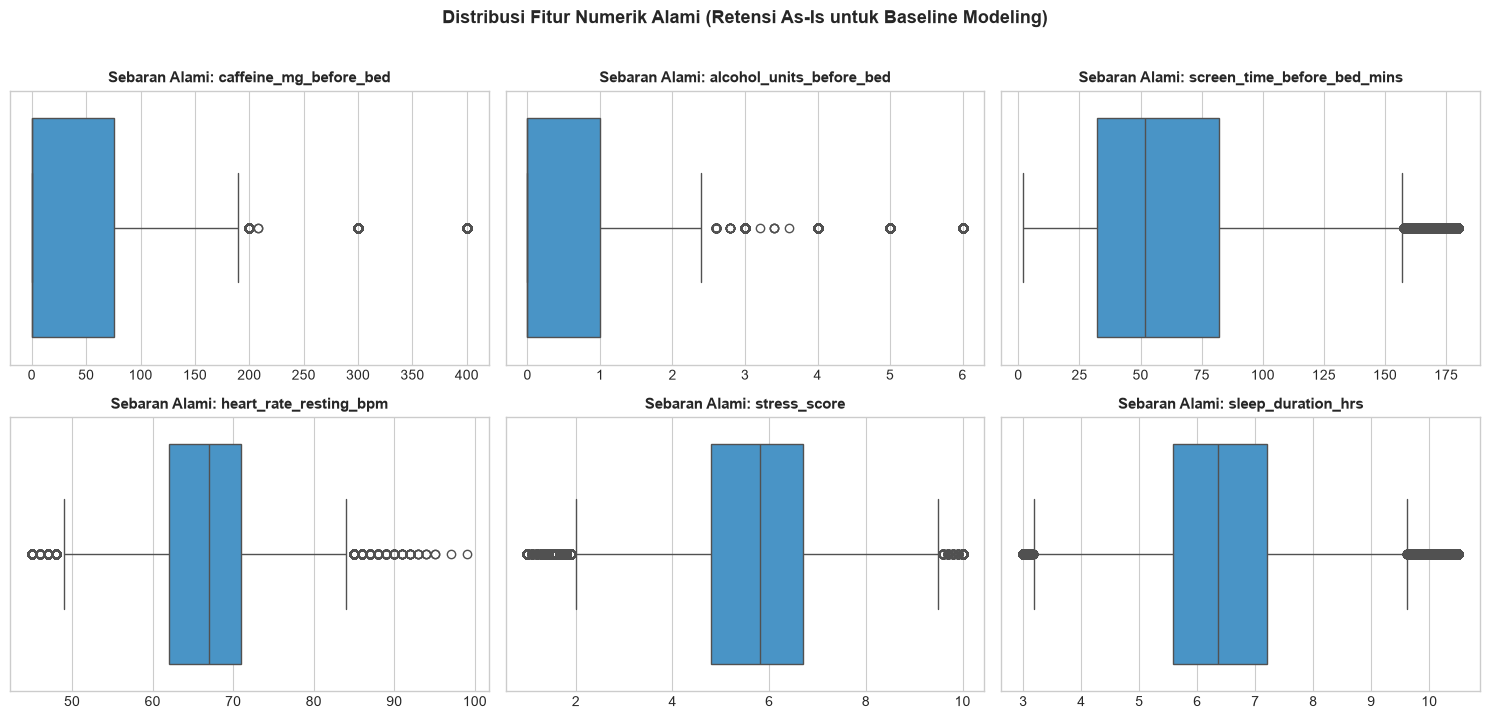

✓ Visualisasi boxplot menampilkan sebaran variasi klinis alami responden.


In [5]:
# Visualisasi Boxplot Sebaran Alami Fitur Utama (Data As-Is)
fitur_plot = [
    'caffeine_mg_before_bed', 'alcohol_units_before_bed', 'screen_time_before_bed_mins',
    'heart_rate_resting_bpm', 'stress_score', 'sleep_duration_hrs'
]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
axes = axes.flatten()

for i, col in enumerate(fitur_plot):
    sns.boxplot(x=df[col], ax=axes[i], color='#3498db')
    axes[i].set_title(f'Sebaran Alami: {col}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')

plt.suptitle('Distribusi Fitur Numerik Alami (Retensi As-Is untuk Baseline Modeling)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
print("✓ Visualisasi boxplot menampilkan sebaran variasi klinis alami responden.")

## 5. Penanganan Ketidakseimbangan Data / Class Imbalance (Jobdesk Utama 2)

### A. Analisis Distribusi Kelas Target (`sleep_disorder_risk`)
Ketidakseimbangan kelas (*class imbalance*) terjadi saat salah satu atau beberapa kelas memiliki jumlah observasi yang jauh melampaui kelas lainnya.
Mari kita visualisasikan sebaran frekuensi dan persentase setiap kelas risiko gangguan tidur.

=== Distribusi Kelas Target Sebelum Penanganan Imbalance ===


,Jumlah Observasi,Persentase (%)
sleep_disorder_risk,,
Healthy,54156,54.16
Mild,33479,33.48
Moderate,8299,8.30
Severe,4066,4.07


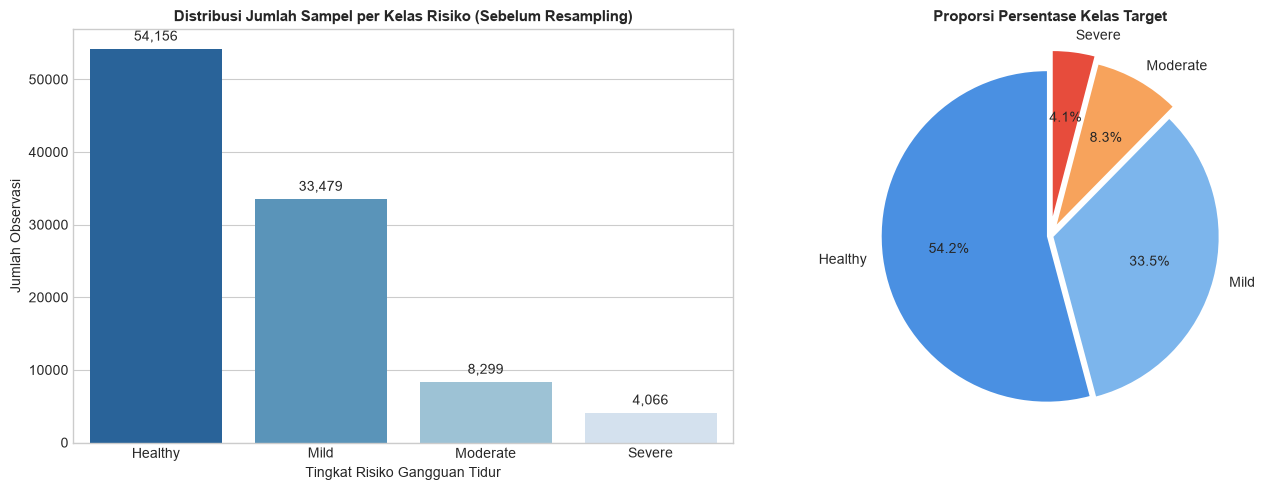

In [6]:
# Menghitung distribusi kelas target
jumlah_kelas = df[kolom_target].value_counts()
persen_kelas = df[kolom_target].value_counts(normalize=True) * 100

tabel_distribusi = pd.DataFrame({
    'Jumlah Observasi': jumlah_kelas,
    'Persentase (%)': persen_kelas.round(2)
})
print("=== Distribusi Kelas Target Sebelum Penanganan Imbalance ===")
display(tabel_distribusi)

# Visualisasi Distribusi Kelas: Countplot & Pie Chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Bar Chart (Countplot)
sns.barplot(x=jumlah_kelas.index, y=jumlah_kelas.values, ax=axes[0], palette='Blues_r')
axes[0].set_title('Distribusi Jumlah Sampel per Kelas Risiko (Sebelum Resampling)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Tingkat Risiko Gangguan Tidur')
axes[0].set_ylabel('Jumlah Observasi')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=10, xytext=(0, 4), textcoords='offset points')

# 2. Pie Chart
axes[1].pie(jumlah_kelas.values, labels=jumlah_kelas.index, autopct='%1.1f%%',
            startangle=90, colors=['#4a90e2', '#7cb5ec', '#f7a35c', '#e74c3c'],
            explode=[0.02, 0.02, 0.08, 0.12])
axes[1].set_title('Proporsi Persentase Kelas Target', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

### B. Identifikasi Dampak Ketidakseimbangan Kelas
Dari analisis di atas, ditemukan ketimpangan kelas yang signifikan:
- **Healthy**: 54.156 observasi (**54.16%**) $\rightarrow$ Kelas Mayoritas Dominan
- **Mild**: 33.479 observasi (**33.48%**) $\rightarrow$ Kelas Mayoritas Menengah
- **Moderate**: 8.299 observasi (**8.30%**) $\rightarrow$ Kelas Minoritas
- **Severe**: 4.066 observasi (**4.07%**) $\rightarrow$ Kelas Minoritas Ekstrem (Rasio ketimpangan > 13 : 1 dibanding Healthy)

**Dampak Serius pada Model Klasifikasi Machine Learning:**
1. **Bias ke Kelas Mayoritas (*Accuracy Paradox*)**: Model klasifikasi yang dilatih pada data timpang akan cenderung memprediksi seluruh responden sebagai *Healthy* atau *Mild*. Secara statistik, akurasi tampak tinggi (~87%), namun model sebenarnya tidak belajar membedakan pola risiko yang sebenarnya.
2. **Kegagalan Deteksi Pasien Kritis (*Low Recall*)**: Pasien dengan risiko *Severe* (parah) dan *Moderate* (sedang) adalah pasien yang paling membutuhkan penanganan medis segera. Ketidakseimbangan kelas menyebabkan nilai *False Negative* tinggi (pasien sakit parah terprediksi sehat), yang berakibat fatal dalam konteks diagnosis kesehatan.

### C. Strategi Penyeimbangan Kelas: SMOTE-NC (Synthetic Minority Over-sampling Technique for Nominal and Continuous)
Untuk mengatasi ketimpangan kelas pada dataset dengan tipe data campuran (*mixed data types* yang terdiri dari fitur kontinu numerik dan fitur kategorikal nominal), kita menerapkan **SMOTE-NC**:
- **Landasan Metodologis**: SMOTE standar mengasumsikan seluruh fitur bersifat kontinu numerik sehingga tidak cocok untuk fitur teks kategori. **SMOTE-NC** dirancang khusus untuk memproses data campuran secara elegan.
- **Mekanisme Sintesis Fitur Kontinu (Numerik)**: SMOTE-NC mengidentifikasi $k$-tetangga terdekat ($k=5$) dari kelas minoritas, lalu melakukan interpolasi linier acak untuk menghasilkan sampel baru yang realistis di dalam ruang fitur kontinu.
- **Mekanisme Sintesis Fitur Nominal (Kategorikal Teks)**: Untuk fitur-fitur teks seperti `gender`, `occupation`, `country`, `chronotype`, `mental_health_condition`, `season`, dan `day_type`, SMOTE-NC **tidak melakukan interpolasi angka desimal semu**, melainkan menetapkan nilai kategori berdasarkan **Modus (*most frequent category*)** dari tetangga-tetangga terdekatnya. Nilai kategori tetap valid dan mempertahankan label teks aslinya.
- **Retensi Kolom `person_id`**: Kolom identitas `person_id` dieksklusikan sementara dari kalkulasi jarak tetangga agar tidak dianggap sebagai variabel biometrik/klinis, kemudian direkonstruksi kembali secara urut integer (1 hingga 216.624) dengan urutan 32 kolom awal yang identik untuk tahapan *Feature Selection* rekan tim.

In [7]:
# 1. Memisahkan Fitur (X) dan Target (y)
# Catatan: person_id dieksklusikan dari kalkulasi jarak tetangga agar tidak diinterpolasi sebagai variabel klinis
X = df.drop(columns=[kolom_target, 'person_id'])
y = df[kolom_target]

# 2. Identifikasi Kolom dan Indeks Kategorikal untuk SMOTE-NC
fitur_kategorikal = X.select_dtypes(include=['object', 'category', 'str']).columns.tolist()
indeks_kategorikal = [X.columns.get_loc(col) for col in fitur_kategorikal]

print(f"Dimensi X sebelum resampling : {X.shape[0]:,} baris x {X.shape[1]} fitur")
print(f"Dimensi y sebelum resampling : {y.shape[0]:,} baris")
print(f"Fitur kategorikal ({len(fitur_kategorikal)} kolom) : {fitur_kategorikal}")
print(f"Indeks fitur kategorikal     : {indeks_kategorikal}")

# 3. Menjalankan SMOTE-NC untuk Menyeimbangkan Kelas
print("\nMenjalankan SMOTE-NC (Synthetic Minority Over-sampling Technique for Nominal and Continuous)...")
t_mulai = time.time()
smote_nc = SMOTENC(categorical_features=indeks_kategorikal, random_state=42)
X_resampled, y_resampled = smote_nc.fit_resample(X, y)
t_selesai = time.time()
print(f"Waktu komputasi SMOTE-NC     : {t_selesai - t_mulai:.2f} detik")

# 4. Rekonstruksi person_id dan Pengurutan Kembali 32 Kolom Utuh Sesuai Struktur Awal
X_resampled['person_id'] = np.arange(1, len(X_resampled) + 1)
df_balanced = pd.concat([X_resampled, y_resampled], axis=1)

# Memastikan urutan kolom identik persis 100% dengan dataset awal df
df_balanced = df_balanced[df.columns]

print("\n=== Penyeimbangan Kelas Berhasil Diterapkan (SMOTE-NC) ===")
print(f"Total baris setelah resampling : {df_balanced.shape[0]:,} baris")
print(f"Total kolom                    : {df_balanced.shape[1]} kolom (32 kolom utuh)")

# Menampilkan tabel distribusi setelah penanganan imbalance
dist_setelah = df_balanced[kolom_target].value_counts()
tabel_setelah = pd.DataFrame({
    'Jumlah Observasi (Setelah SMOTE-NC)': dist_setelah,
    'Persentase (%)': (df_balanced[kolom_target].value_counts(normalize=True) * 100).round(2)
})
display(tabel_setelah)

Dimensi X sebelum resampling : 100,000 baris x 30 fitur
Dimensi y sebelum resampling : 100,000 baris
Fitur kategorikal (7 kolom) : ['gender', 'occupation', 'country', 'chronotype', 'mental_health_condition', 'season', 'day_type']
Indeks fitur kategorikal     : [1, 2, 4, 19, 20, 26, 27]

Menjalankan SMOTE-NC (Synthetic Minority Over-sampling Technique for Nominal and Continuous)...
Waktu komputasi SMOTE-NC     : 32.23 detik

=== Penyeimbangan Kelas Berhasil Diterapkan (SMOTE-NC) ===
Total baris setelah resampling : 216,624 baris
Total kolom                    : 32 kolom (32 kolom utuh)


,Jumlah Observasi (Setelah SMOTE-NC),Persentase (%)
sleep_disorder_risk,,
Healthy,54156,25.0
Severe,54156,25.0
Mild,54156,25.0
Moderate,54156,25.0


### D. Visualisasi Komparasi Distribusi Kelas (Sebelum vs Sesudah Resampling SMOTE-NC)
Visualisasi berikut memperlihatkan keberhasilan transformasi distribusi data: dari kondisi timpang (*imbalanced*) menjadi seimbang sempurna (*balanced*) melalui **SMOTE-NC**, dengan masing-masing kelas memiliki **54.156 observasi (25.0%)**.

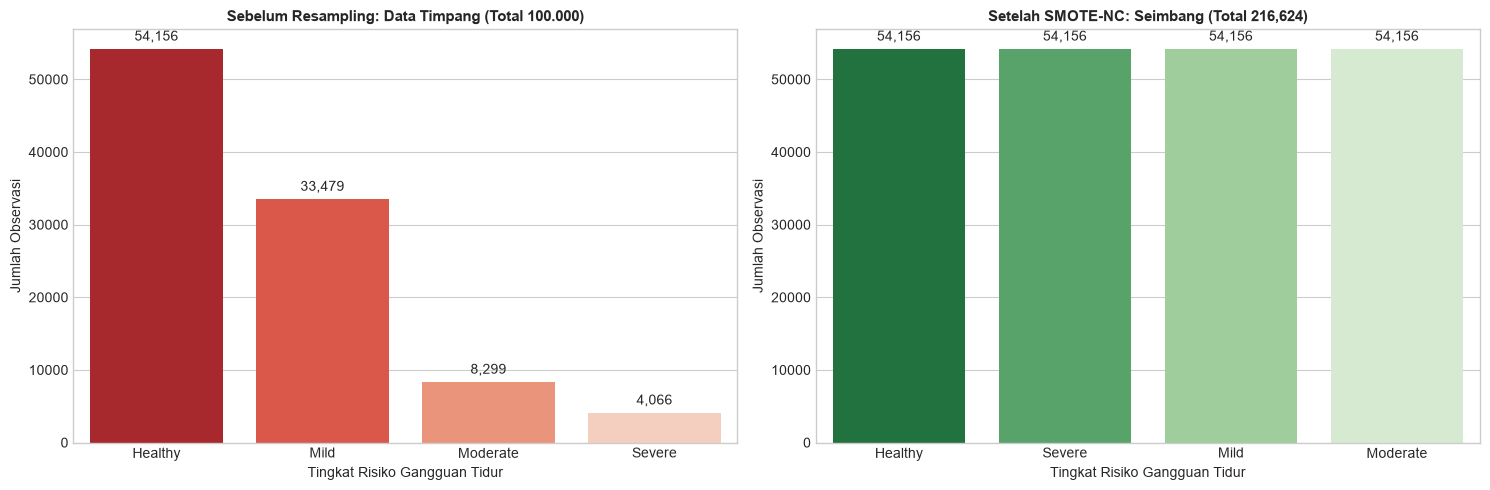

✓ Seluruh kelas target telah memiliki bobot representasi yang seimbang secara proporsional via SMOTE-NC.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Plot Sebelum Resampling
sns.barplot(x=jumlah_kelas.index, y=jumlah_kelas.values, ax=axes[0], palette='Reds_r')
axes[0].set_title('Sebelum Resampling: Data Timpang (Total 100.000)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Tingkat Risiko Gangguan Tidur')
axes[0].set_ylabel('Jumlah Observasi')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=10, xytext=(0, 4), textcoords='offset points')

# 2. Plot Setelah Resampling
sns.barplot(x=dist_setelah.index, y=dist_setelah.values, ax=axes[1], palette='Greens_r')
axes[1].set_title(f'Setelah SMOTE-NC: Seimbang (Total {len(df_balanced):,})', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Tingkat Risiko Gangguan Tidur')
axes[1].set_ylabel('Jumlah Observasi')
for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=10, xytext=(0, 4), textcoords='offset points')

plt.tight_layout()
plt.show()
print("✓ Seluruh kelas target telah memiliki bobot representasi yang seimbang secara proporsional via SMOTE-NC.")

## 6. Penyimpanan Dataset & Rangkuman Penyelesaian Jobdesk

Dataset yang telah dibersihkan dari *missing values* dan diseimbangkan kelasnya diekspor sebagai berkas siap pakai (32 kolom utuh) untuk tahapan kerja rekan tim berikutnya:
1. **`dataset_imputed.csv`**: Dataset bersih utuh (100.000 baris × **32 kolom**, 0% missing value, distribusi target asli dipertahankan, nilai ekstrem dipertahankan alami).
2. **`dataset_balanced.csv`**: Dataset bersih seimbang sintetis (216.624 baris × **32 kolom**, 0% missing value, 4 kelas target seimbang masing-masing 54.156 sampel via SMOTE-NC).

In [9]:
# 1. Menyimpan dataset hasil imputasi (100.000 baris x 32 kolom)
output_imputed = 'dataset_imputed.csv'
df.to_csv(output_imputed, index=False)
print(f"✓ File '{output_imputed}' berhasil disimpan ({df.shape[0]:,} baris x {df.shape[1]} kolom).")

# 2. Menyimpan dataset hasil penyeimbangan kelas (216.624 baris x 32 kolom)
output_balanced = 'dataset_balanced.csv'
df_balanced.to_csv(output_balanced, index=False)
print(f"✓ File '{output_balanced}' berhasil disimpan ({df_balanced.shape[1]} kolom x {df_balanced.shape[0]:,} baris).")

print("\n" + "=" * 65)
print("RANGKUMAN PENYELESAIAN JOBDESK DATA PREPARATION (BAB 3)")
print("=" * 65)
print(f"[✓] Retensi Struktur Data : 32 kolom utuh dipertahankan untuk Feature Selection tim")
print("[✓] Handling Missing Value : 0% missing values pada 32 kolom (KNN Imputer k=5 + Modus)")
print("[✓] Handling Outliers      : Dianalisis lengkap & dipertahankan As-Is untuk baseline model")
print(f"[✓] Handling Imbalance     : 4 kelas seimbang ({len(df_balanced)//4:,} sampel per kelas via SMOTE-NC)")
print(f"[✓] Berkas Output          : '{output_imputed}' & '{output_balanced}' (32 kolom utuh)")
print("=" * 65)
print("JOBDESK PENYIAPAN DATA SELESAI DENGAN SEMPURNA!")

✓ File 'dataset_imputed.csv' berhasil disimpan (100,000 baris x 32 kolom).
✓ File 'dataset_balanced.csv' berhasil disimpan (32 kolom x 216,624 baris).

RANGKUMAN PENYELESAIAN JOBDESK DATA PREPARATION (BAB 3)
[✓] Retensi Struktur Data : 32 kolom utuh dipertahankan untuk Feature Selection tim
[✓] Handling Missing Value : 0% missing values pada 32 kolom (KNN Imputer k=5 + Modus)
[✓] Handling Outliers      : Dianalisis lengkap & dipertahankan As-Is untuk baseline model
[✓] Handling Imbalance     : 4 kelas seimbang (54,156 sampel per kelas via SMOTE-NC)
[✓] Berkas Output          : 'dataset_imputed.csv' & 'dataset_balanced.csv' (32 kolom utuh)
JOBDESK PENYIAPAN DATA SELESAI DENGAN SEMPURNA!
